# Lineare Regression mit einem metrischen Ziel: Diabetes-Datensatz

Der Iris-Datensatz besitzt eine kategoriale Zielvariablen und ist daher nur für Beantwortung von Klassifikationsproblmen geeignet. Für die Einführung der linearen Regression wird hier der in `scikit-learn` enthaltene **Diabetes-Datensatz** verwendet. Die Zielvariable ist kontinuierlich und beschreibt die Krankheitsprogression ein Jahr nach der Baseline-Messung.

Zunächst wird mit dem Merkmal `bmi` eine **einfache lineare Regression** gerechnet. Anschließend werden die Least-Squares-Lösung, die Verlustfunktion und der Gradientenabstieg aufgezeigt.

In [4]:
%pip install statsmodels ## bei mir funktionierte die manuelle Installation nicht 

  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 9.0 MB/s eta 0:00:00 0:00:01m
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)
Note: you may need to restart the kernel to use updated packages.


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

plt.rcParams['figure.figsize'] = (8, 5)

## 1. Daten laden und prüfen

In [30]:
data = load_diabetes(as_frame=True)
df = data.frame.copy()
df.head() ## hier kann mir einer Zahl angegeben werden, wie viele Zeilen des Datensatzes ausgegeben werden sollen
## target = Zielvariable 

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [ ]:
## Hinweis: Die Features sind mean centered (Interpretation 1 Standard Deviation)
## Interpretation eines Koeffizienten: Verändert sich das Feature um eine Standard Deviation, wie verändert sich 
## die disease progression ("target variable")

In [31]:
print('Form:', df.shape)
print('Fehlende Werte:', int(df.isna().sum().sum()))
df.describe().T

Form: (442, 11)
Fehlende Werte: 0


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


In [32]:
## Datenbereinigung und Plausibilitätschecks wurden hier zu Demonstrationszwecken übersprungen, sollten aber stets vorab durchgeführt

## 2. Einfache lineare Regression: `bmi` → `target`

Wir verwenden bewusst zunächst nur ein Merkmal. Dadurch kann die Regressionsgerade direkt visualisiert werden.

In [33]:
X = df[['bmi']]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print(f'Achsenabschnitt beta_0: {model.intercept_:.3f}')
print(f'Steigung beta_1: {model.coef_[0]:.3f}')

Achsenabschnitt beta_0: 152.077
Steigung beta_1: 975.277


In [35]:
## Etwas mehr Informationen ergänzen für die Interpretation
X = df[['bmi']]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# statsmodels braucht den Achsenabschnitt explizit als Konstante
X_train_sm = sm.add_constant(X_train)

model_sm = sm.OLS(y_train, X_train_sm).fit()
print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.350
Model:                            OLS   Adj. R-squared:                  0.348
Method:                 Least Squares   F-statistic:                     176.9
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           1.35e-32
Time:                        11:53:29   Log-Likelihood:                -1839.5
No. Observations:                 331   AIC:                             3683.
Df Residuals:                     329   BIC:                             3691.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        152.0765      3.461     43.942      0.0

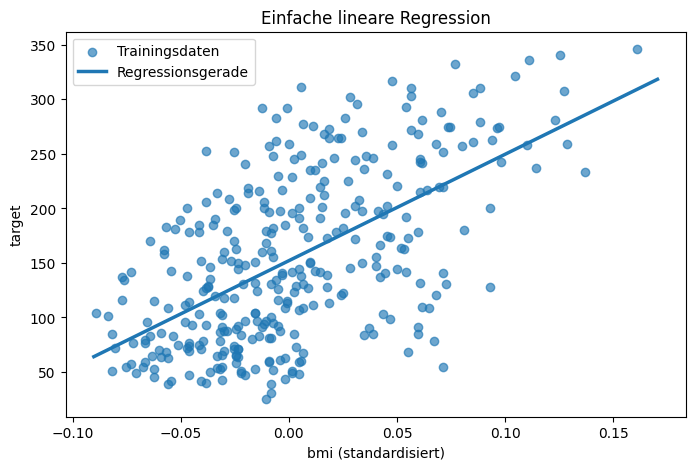

In [36]:
## Visualisierung der gefitteten Regressionsgeraden
x_grid = np.linspace(X['bmi'].min(), X['bmi'].max(), 200).reshape(-1, 1)
y_grid = model.predict(pd.DataFrame(x_grid, columns=['bmi']))

fig, ax = plt.subplots()
ax.scatter(X_train['bmi'], y_train, alpha=0.65, label='Trainingsdaten')
ax.plot(x_grid[:, 0], y_grid, linewidth=2.5, label='Regressionsgerade')
ax.set_xlabel('bmi (standardisiert)')
ax.set_ylabel('target')
ax.set_title('Einfache lineare Regression')
ax.legend()
plt.show()

## 3. Vorhersagen, Residuen und Verlust

In [37]:
y_pred = model.predict(X_test)
results = pd.DataFrame({
    'y': y_test.to_numpy(),
    'y_hat': y_pred,
})
results['residuum'] = results['y'] - results['y_hat']
results['quadratischer_loss'] = results['residuum'] ** 2
results.head(10).round(2)

,y,y_hat,residuum,quadratischer_loss
0,219.0,146.02,72.98,5325.50
1,70.0,188.07,-118.07,13940.67
2,202.0,148.13,53.87,2902.37
3,230.0,202.79,27.21,740.55
4,111.0,132.36,-21.36,456.20
5,84.0,128.15,-44.15,1949.59
6,242.0,318.42,-76.42,5839.27
7,272.0,196.48,75.52,5703.28
8,94.0,64.03,29.97,898.01
9,96.0,167.05,-71.05,5047.72


In [38]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f'MSE auf Testdaten: {mse:.2f}')
print(f'R² auf Testdaten: {r2:.3f}')

MSE auf Testdaten: 3775.62
R² auf Testdaten: 0.317


In [ ]:
## Gemeinsame Interpretation

### Aufgabe 1

Wählen Sie eine Zeile aus `results` aus und prüfen Sie die Beziehung

$e_i = y_i - \hat y_i$

und

$L_i=e_i^2$

per Hand.

## 4. Least-Squares-Lösung von Hand (analytische Vorgehensweise)

In [39]:
x = X_train['bmi'].to_numpy()
y_tr = y_train.to_numpy()

x_bar = x.mean()
y_bar = y_tr.mean()

beta_1 = np.sum((x - x_bar) * (y_tr - y_bar)) / np.sum((x - x_bar) ** 2)
beta_0 = y_bar - beta_1 * x_bar

print(f'beta_0 analytisch: {beta_0:.3f}')
print(f'beta_1 analytisch: {beta_1:.3f}')
print(f'beta_0 sklearn:    {model.intercept_:.3f}')
print(f'beta_1 sklearn:    {model.coef_[0]:.3f}')

beta_0 analytisch: 152.077
beta_1 analytisch: 975.277
beta_0 sklearn:    152.077
beta_1 sklearn:    975.277


## 5. Zielfunktion als Funktion der Parameter

Für eine Beobachtung verwenden wir den quadratischen Fehler als Verlustfunktion. Über alle Trainingsbeobachtungen wird daraus die MSE-Zielfunktion:

$J(\beta_0,\beta_1)=\frac{1}{n}\sum_i(y_i-\beta_0-\beta_1x_i)^2$.

In [40]:
def mse_objective(beta_0, beta_1, x, y):
    y_hat = beta_0 + beta_1 * x
    return np.mean((y - y_hat) ** 2)

print('MSE am geschätzten Optimum:', mse_objective(beta_0, beta_1, x, y_tr))
print('MSE bei beta_0=0, beta_1=0:', mse_objective(0, 0, x, y_tr))

MSE am geschätzten Optimum: 3930.9895155330532
MSE bei beta_0=0, beta_1=0: 29866.82175226586


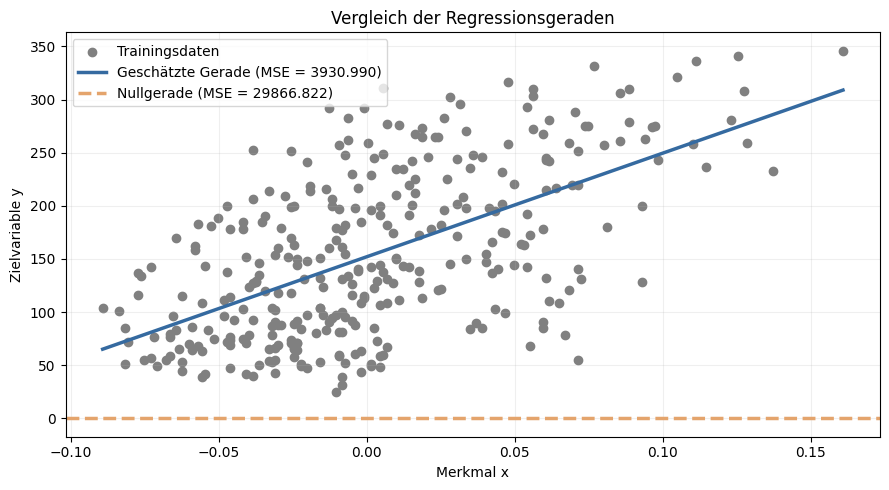

In [41]:
# Vorhandene Daten für die Visualisierung
x_werte = np.asarray(x).ravel()
y_werte = np.asarray(y_tr).ravel()

# X-Werte für beide Geraden
x_linie = np.linspace(x_werte.min(), x_werte.max(), 200)

# Geschätzte Gerade mit vorhandenen Parametern
y_optimum = beta_0 + beta_1 * x_linie

# Vorhandene MSE-Funktion verwenden
mse_optimum = mse_objective(beta_0, beta_1, x_werte, y_werte)
mse_null = mse_objective(0, 0, x_werte, y_werte)

# Visualisierung
plt.figure(figsize=(9, 5))

plt.scatter(x_werte, y_werte, color="gray",
            label="Trainingsdaten")

plt.plot(x_linie, y_optimum, color="#356AA0",
         linewidth=2.5,
         label=f"Geschätzte Gerade (MSE = {mse_optimum:.3f})")

plt.axhline(y=0, color="#E4A46C",
            linewidth=2.5, linestyle="--",
            label=f"Nullgerade (MSE = {mse_null:.3f})")

plt.xlabel("Merkmal x")
plt.ylabel("Zielvariable y")
plt.title("Vergleich der Regressionsgeraden")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 6. Gradientenabstieg von Hand implementieren

In [42]:
def gradient_descent(x, y, learning_rate=0.1, n_iter=2000):
    beta_0 = 0.0
    beta_1 = 0.0
    history = []
    n = len(x)

    for iteration in range(n_iter):
        y_hat = beta_0 + beta_1 * x
        error = y_hat - y

        grad_b0 = (2 / n) * np.sum(error)
        grad_b1 = (2 / n) * np.sum(error * x)

        beta_0 -= learning_rate * grad_b0
        beta_1 -= learning_rate * grad_b1

        if iteration % 10 == 0:
            history.append((iteration, beta_0, beta_1, np.mean(error ** 2)))

    return beta_0, beta_1, pd.DataFrame(
        history, columns=['iteration', 'beta_0', 'beta_1', 'mse']
    )

gd_b0, gd_b1, history = gradient_descent(x, y_tr, learning_rate=0.5, n_iter=5000)
print(f'beta_0 Gradientenabstieg: {gd_b0:.3f}')
print(f'beta_1 Gradientenabstieg: {gd_b1:.3f}')
print(f'beta_0 analytisch:        {beta_0:.3f}')
print(f'beta_1 analytisch:        {beta_1:.3f}')

# Der Gradientenabstieg bestimmt die Regressionsparameter beta_0 und beta_1
# durch schrittweise Minimierung der MSE-Verlustfunktion.
# Ausgehend von beta_0 = 0 und beta_1 = 0 werden in jeder Iteration
# die Vorhersagefehler und die Gradienten der Verlustfunktion berechnet.
# Anschließend werden beide Parameter mithilfe der Lernrate aktualisiert.
# Alle 10 Iterationen wird der Trainingsverlauf gespeichert.
# Abschließend werden die geschätzten Parameter mit der analytischen
# OLS-Lösung verglichen.

beta_0 Gradientenabstieg: 152.077
beta_1 Gradientenabstieg: 975.263
beta_0 analytisch:        152.077
beta_1 analytisch:        975.277


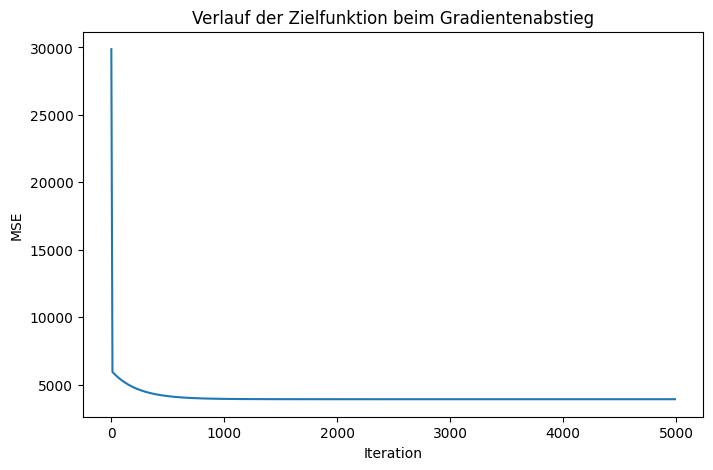

In [43]:
fig, ax = plt.subplots()
ax.plot(history['iteration'], history['mse'])
ax.set_xlabel('Iteration')
ax.set_ylabel('MSE')
ax.set_title('Verlauf der Zielfunktion beim Gradientenabstieg')
plt.show()

### Aufgabe 2: Lernrate untersuchen

Führen Sie den Gradientenabstieg mit verschiedenen Lernraten aus, beispielsweise `0.01`, `0.1`, `0.5`, `1.0` und `2.0`. Vergleichen Sie den Verlauf der Zielfunktion. Welche Lernrate konvergiert schnell? Bei welcher Lernrate wird das Verfahren instabil?

## 7. Residuen visualisieren

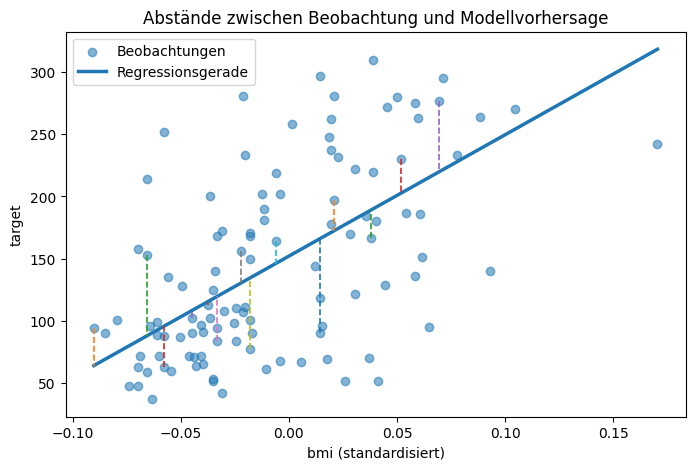

In [44]:
sample = X_test.copy()
sample['y'] = y_test
sample['y_hat'] = y_pred
sample = sample.sort_values('bmi').iloc[::8]

fig, ax = plt.subplots()
ax.scatter(X_test['bmi'], y_test, alpha=0.55, label='Beobachtungen')
ax.plot(x_grid[:, 0], y_grid, linewidth=2.5, label='Regressionsgerade')
for _, row in sample.iterrows():
    ax.plot([row['bmi'], row['bmi']], [row['y'], row['y_hat']], linestyle='--', linewidth=1.2)
ax.set_xlabel('bmi (standardisiert)')
ax.set_ylabel('target')
ax.set_title('Abstände zwischen Beobachtung und Modellvorhersage')
ax.legend()
plt.show()

## 8. Erweiterung: multiple lineare Regression

In [45]:
X_all = df.drop(columns='target')
y = df['target']
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X_all, y, test_size=0.25, random_state=42
)

multiple_model = LinearRegression().fit(X_train_all, y_train_all)
y_pred_all = multiple_model.predict(X_test_all)

print(f'MSE einfaches Modell: {mse:.2f}')
print(f'MSE multiples Modell: {mean_squared_error(y_test_all, y_pred_all):.2f}')
print(f'R² einfaches Modell: {r2:.3f}')
print(f'R² multiples Modell: {r2_score(y_test_all, y_pred_all):.3f}')

MSE einfaches Modell: 3775.62
MSE multiples Modell: 2848.31
R² einfaches Modell: 0.317
R² multiples Modell: 0.485


In [46]:
coef_table = pd.DataFrame({
    'Merkmal': X_all.columns,
    'Koeffizient': multiple_model.coef_
}).sort_values('Koeffizient')
coef_table

,Merkmal,Koeffizient
4,s1,-918.502905
1,sex,-241.990907
9,s6,26.324582
0,age,47.749681
6,s3,116.950164
7,s4,269.492303
3,bp,381.562862
5,s2,508.257783
2,bmi,531.971063
8,s5,695.808117


In [47]:
## mit statsmodels komplett
X_all = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.25, random_state=42
)

# statsmodels braucht den Achsenabschnitt explizit als Konstante
X_train_sm = sm.add_constant(X_train)

model_sm = sm.OLS(y_train, X_train_sm).fit()
print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.519
Model:                            OLS   Adj. R-squared:                  0.504
Method:                 Least Squares   F-statistic:                     34.53
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           2.97e-45
Time:                        12:15:23   Log-Likelihood:                -1789.5
No. Observations:                 331   AIC:                             3601.
Df Residuals:                     320   BIC:                             3643.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        151.6652      3.023     50.162      0.0

In [ ]:
## Beispielhafte Interpretation:
## Einfluss Alter: Kein signifikanter Einfluss auf die disease progression (Fortschreiten der Erkrankung)
## Einfluss BMI: Erhöht sich der BMI um eine Standardabweichung so steigt die disease progression signifikant um 
## 531 Einheiten

In [ ]:
## Hinweis: Die Features sind mean centered (Interpretation 1 Standard Deviation)